# Projeto Prático de Classificação — CIN0209
## Online Shoppers Purchasing Intention Dataset

**Dupla:** Eduardo Neves e Wallace Santana

**Entrega 1** — exploração e baselines

## Seção 1 — O problema e os dados

**Pergunta que o projeto responde:** dado o comportamento de navegação de um visitante durante uma sessão em um site de e-commerce (páginas visitadas, tempo em cada categoria de página, métricas de engajamento, contexto de acesso), é possível prever se essa sessão vai terminar em compra (`Revenue = True`) ou não (`Revenue = False`)? O objetivo é classificar sessões já concluídas — não fazer previsão em tempo real durante a navegação.

**Fonte e licença:** [Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset), UCI Machine Learning Repository (ID 468). Dados públicos, coletados por Sakar, Polat, Katircioglu e Kastro (2018), disponibilizados para uso acadêmico e de pesquisa.

**Tamanho:** 12.330 sessões, cada uma de um usuário distinto ao longo de 1 ano (evita viés de campanha específica, data especial ou perfil de usuário). 10 atributos numéricos + 8 categóricos, além do alvo.

**Atributos:**

| Atributo | Descrição |
|---|---|
| `Administrative` | Nº de páginas administrativas visitadas na sessão |
| `Administrative_Duration` | Tempo total (s) gasto em páginas administrativas |
| `Informational` | Nº de páginas informativas visitadas |
| `Informational_Duration` | Tempo total (s) gasto em páginas informativas |
| `ProductRelated` | Nº de páginas de produto visitadas |
| `ProductRelated_Duration` | Tempo total (s) gasto em páginas de produto |
| `BounceRates` | % de visitantes que entraram por aquela página e saíram sem interagir mais |
| `ExitRates` | % de visualizações de página que foram a última da sessão |
| `PageValues` | Valor médio da página, calculado a partir de métricas de e-commerce (proxy de intenção de compra) |
| `SpecialDay` | Proximidade da sessão a uma data especial (ex.: Dia dos Namorados), de 0 a 1 |
| `Month` | Mês da sessão |
| `OperatingSystems` | Sistema operacional (código categórico) |
| `Browser` | Navegador (código categórico) |
| `Region` | Região geográfica (código categórico) |
| `TrafficType` | Tipo de tráfego de origem (código categórico) |
| `VisitorType` | Novo visitante, recorrente ou outro |
| `Weekend` | Se a sessão ocorreu em um fim de semana (booleano) |
| **`Revenue`** | **Alvo** — se a sessão terminou em compra (booleano) |

**Alvo:** `Revenue` (binário: True/False). Já vem construído no dataset, não precisa ser derivado.

## Seção 2 — Exploração

In [ ]:
# Instalação e imports
!pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')


In [ ]:
# Carregamento do dataset direto do UCI (ID 468)
dataset = fetch_ucirepo(id=468)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)
df.head()


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Dimensões e tipos

In [ ]:
print(f"Formato: {df.shape[0]} linhas, {df.shape[1]} colunas")
print()
df.info()


Formato: 12330 linhas, 18 colunas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  

### Valores faltantes

In [ ]:
faltantes = df.isnull().sum()
faltantes_pct = (faltantes / len(df) * 100).round(2)
pd.DataFrame({'faltantes': faltantes, '%': faltantes_pct}).sort_values('faltantes', ascending=False)


,faltantes,%
Administrative,0,0.0
Administrative_Duration,0,0.0
Informational,0,0.0
Informational_Duration,0,0.0
ProductRelated,0,0.0
ProductRelated_Duration,0,0.0
BounceRates,0,0.0
ExitRates,0,0.0
PageValues,0,0.0
SpecialDay,0,0.0


### Balanceamento das classes (alvo)

Revenue
False    10422
True      1908
Name: count, dtype: int64

Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


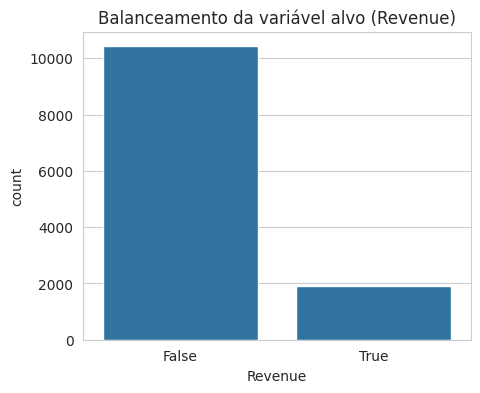

In [ ]:
contagem = df['Revenue'].value_counts()
percentual = df['Revenue'].value_counts(normalize=True).round(4) * 100

print(contagem)
print()
print(percentual)

plt.figure(figsize=(5,4))
sns.countplot(data=df, x='Revenue')
plt.title('Balanceamento da variável alvo (Revenue)')
plt.show()


### Distribuições dos atributos numéricos

In [ ]:
atributos_numericos = ['Administrative', 'Administrative_Duration', 'Informational',
                       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

df[atributos_numericos].describe()


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000


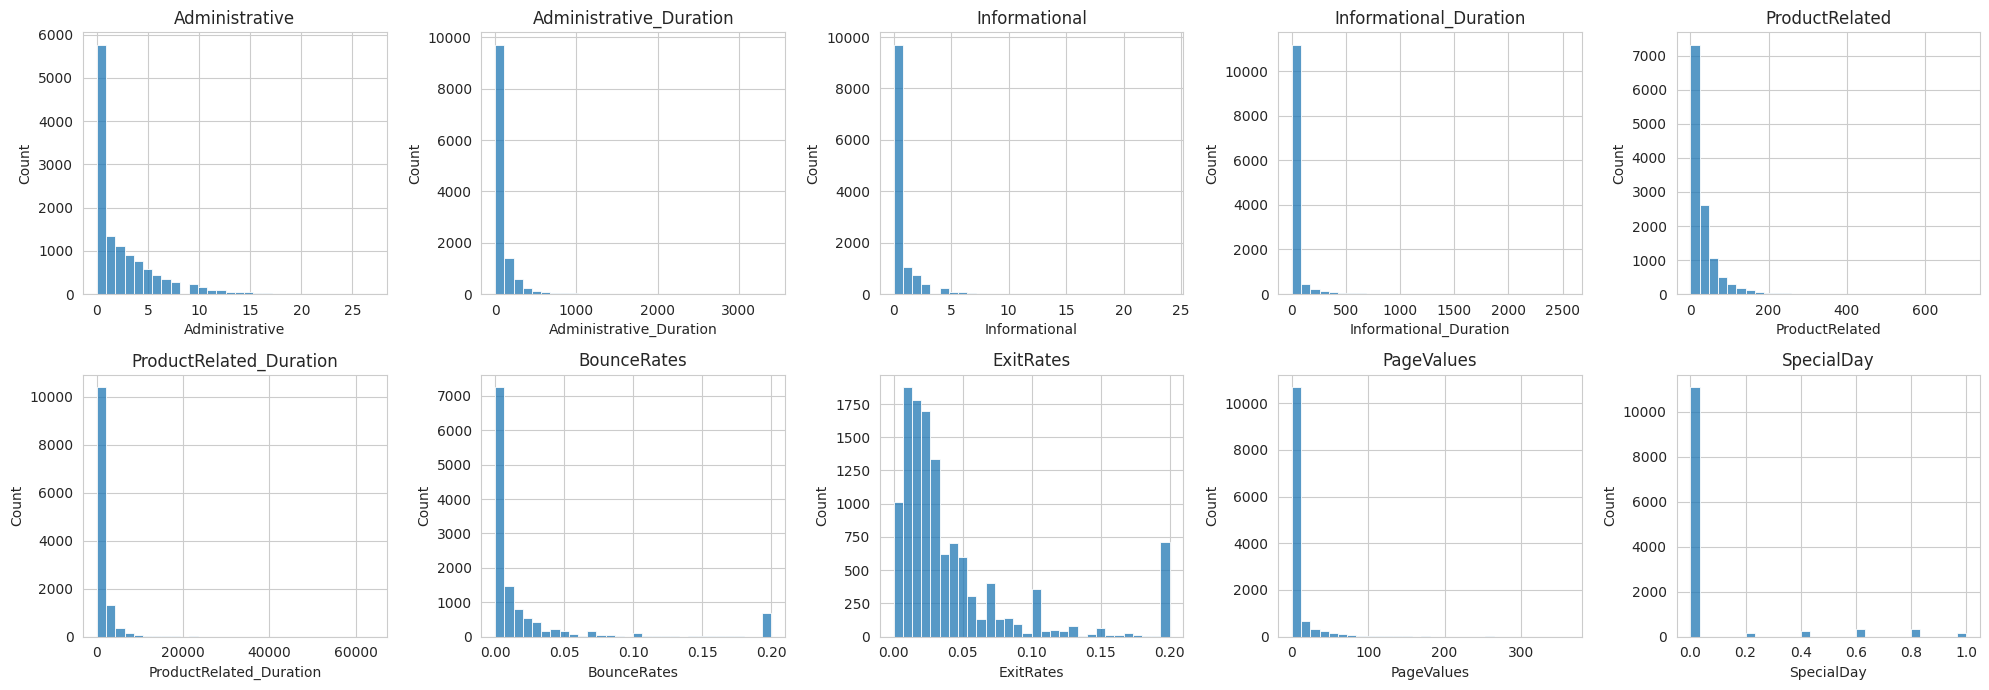

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
axes = axes.flatten()

for i, col in enumerate(atributos_numericos):
    sns.histplot(df[col], bins=30, ax=axes[i], kde=False)
    axes[i].set_title(col)

plt.tight_layout()
plt.show()


### Distribuições dos atributos categóricos

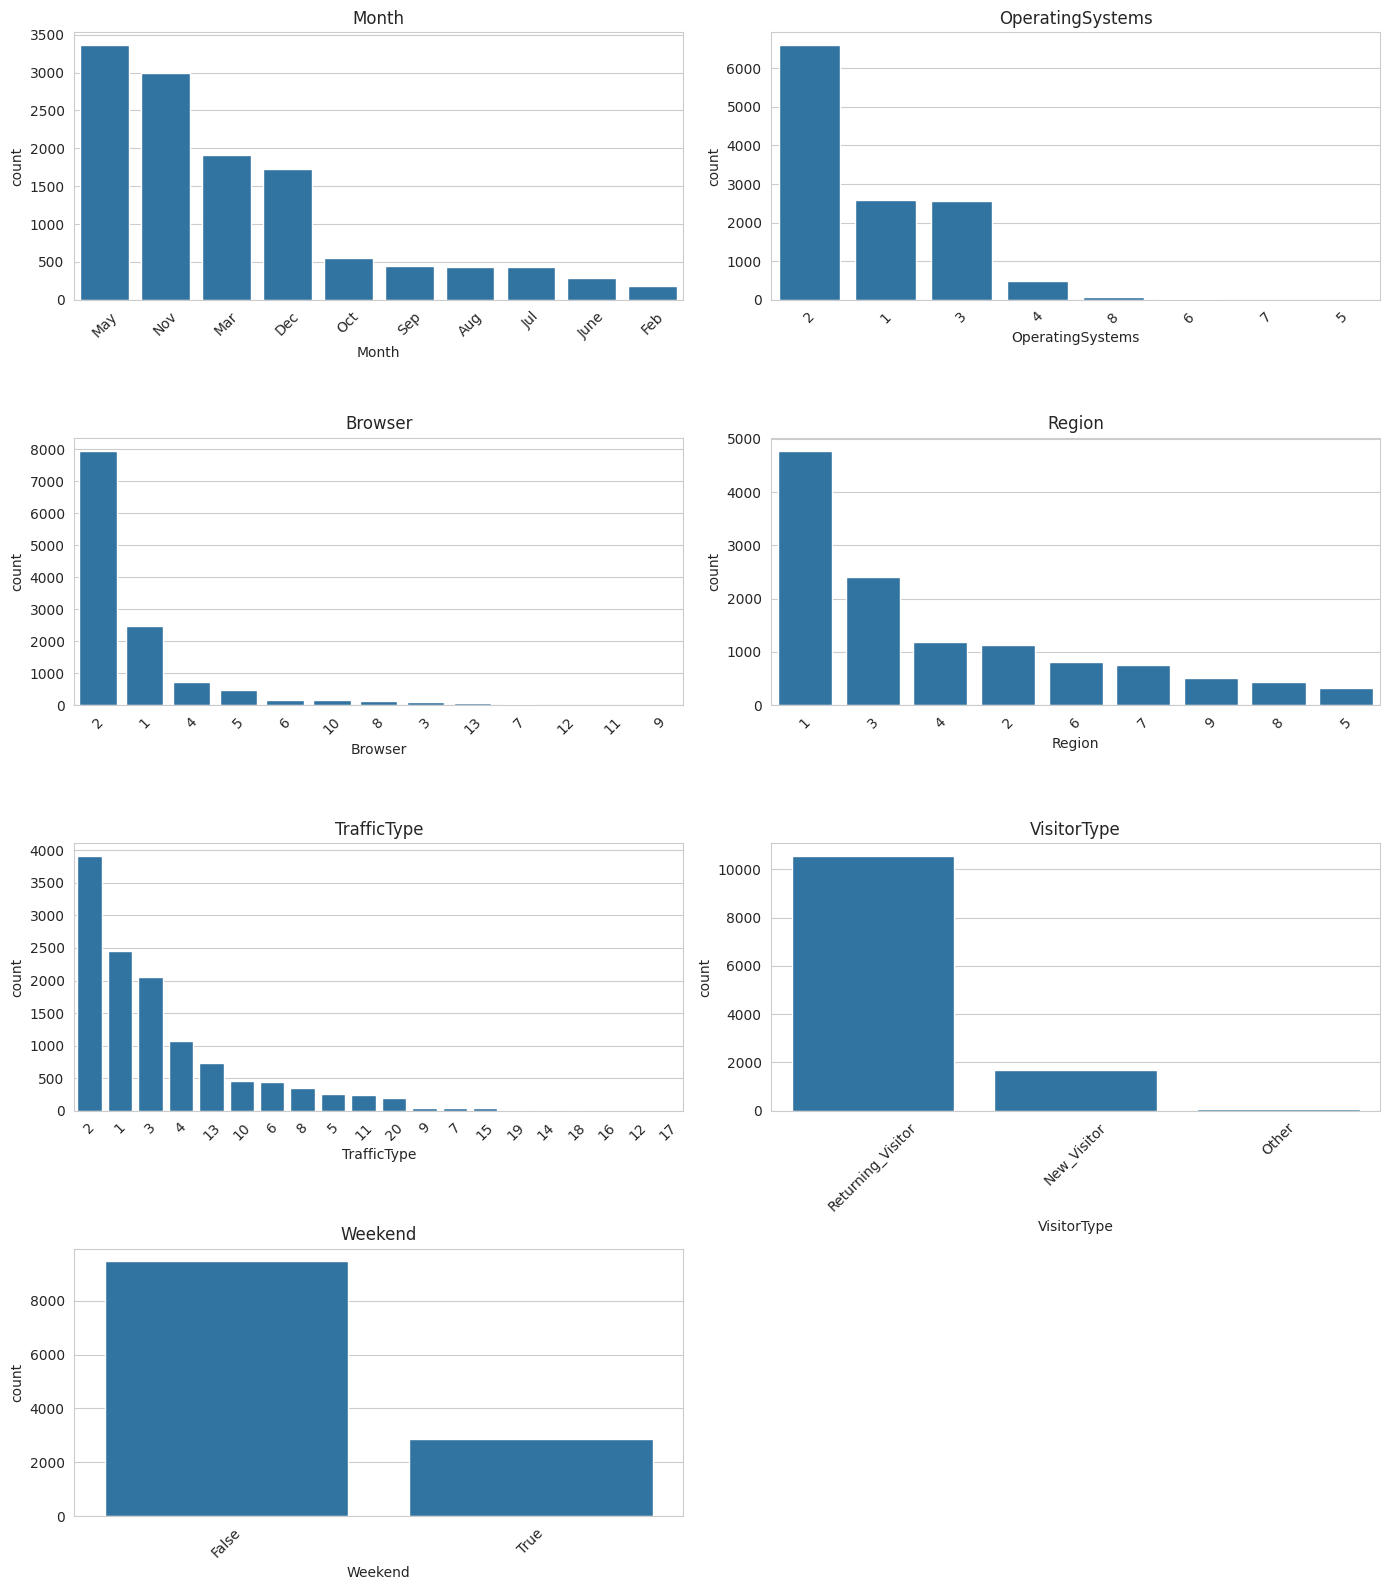

In [ ]:
atributos_categoricos = ['Month', 'OperatingSystems', 'Browser', 'Region',
                         'TrafficType', 'VisitorType', 'Weekend']

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(atributos_categoricos):
    ordem = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=ordem, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

fig.delaxes(axes[-1])  # sobra um eixo (7 categóricos em grade 4x2)
plt.tight_layout()
plt.show()


### Relação dos atributos numéricos com o alvo

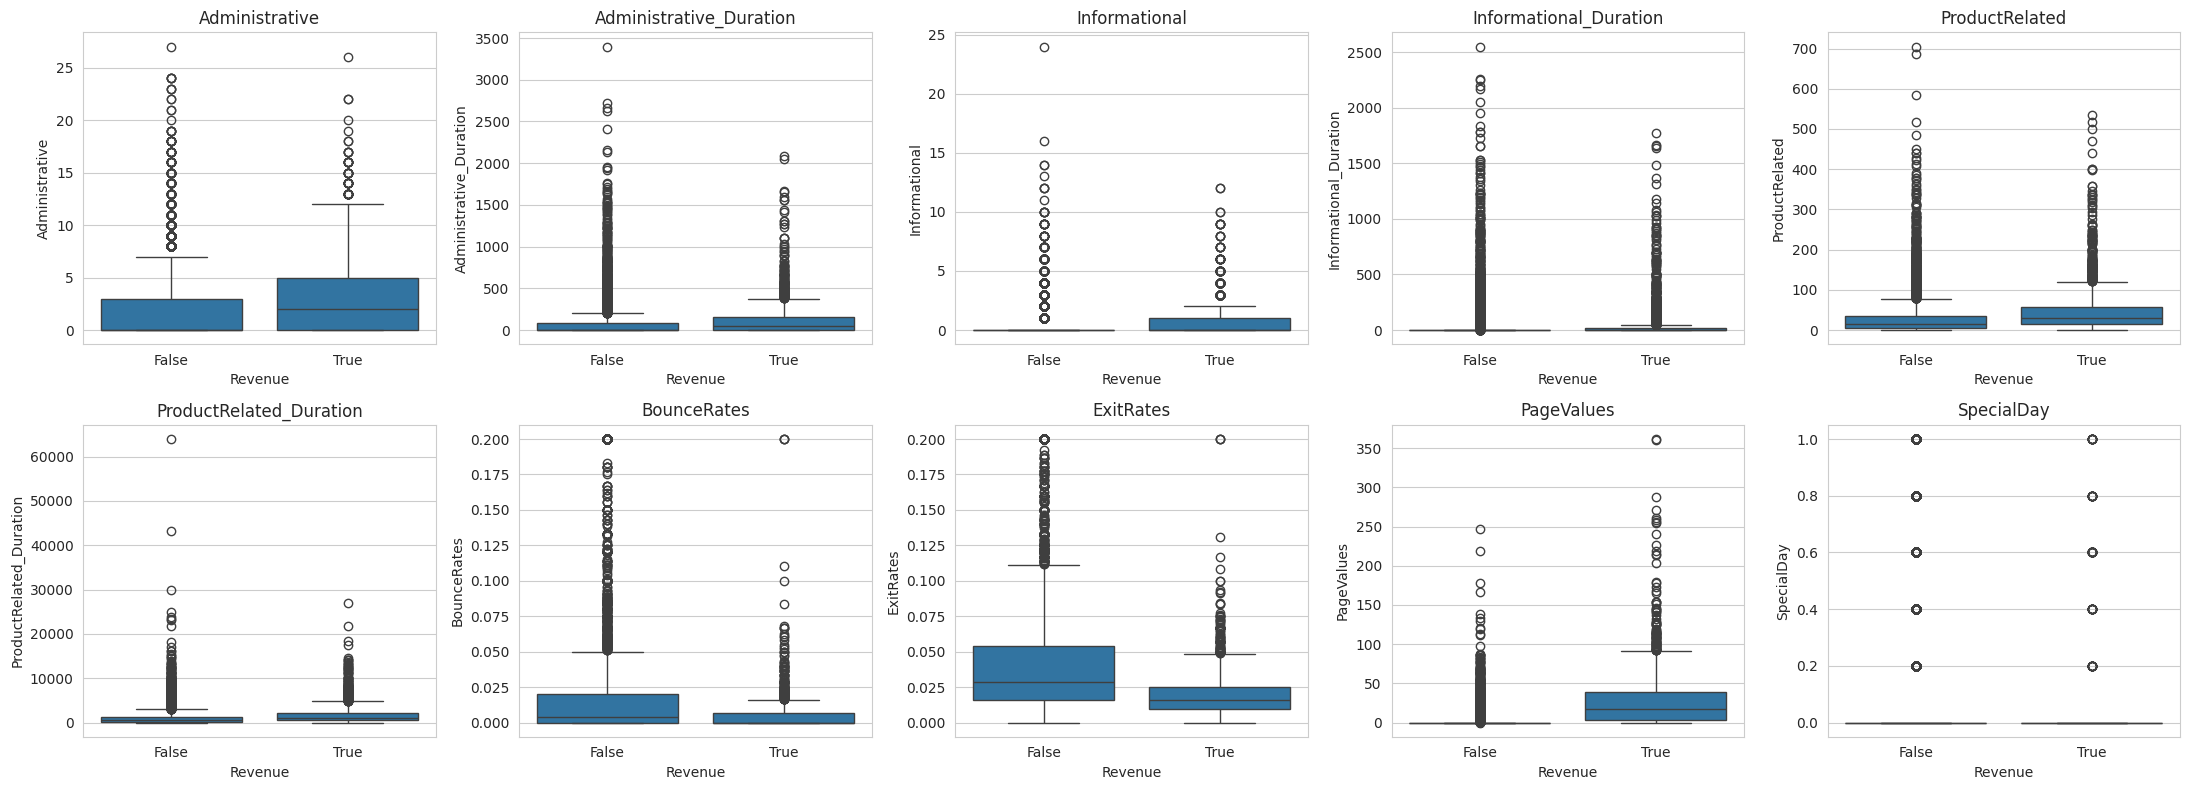

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()

for i, col in enumerate(atributos_numericos):
    sns.boxplot(data=df, x='Revenue', y=col, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()


### Relação dos atributos categóricos com o alvo

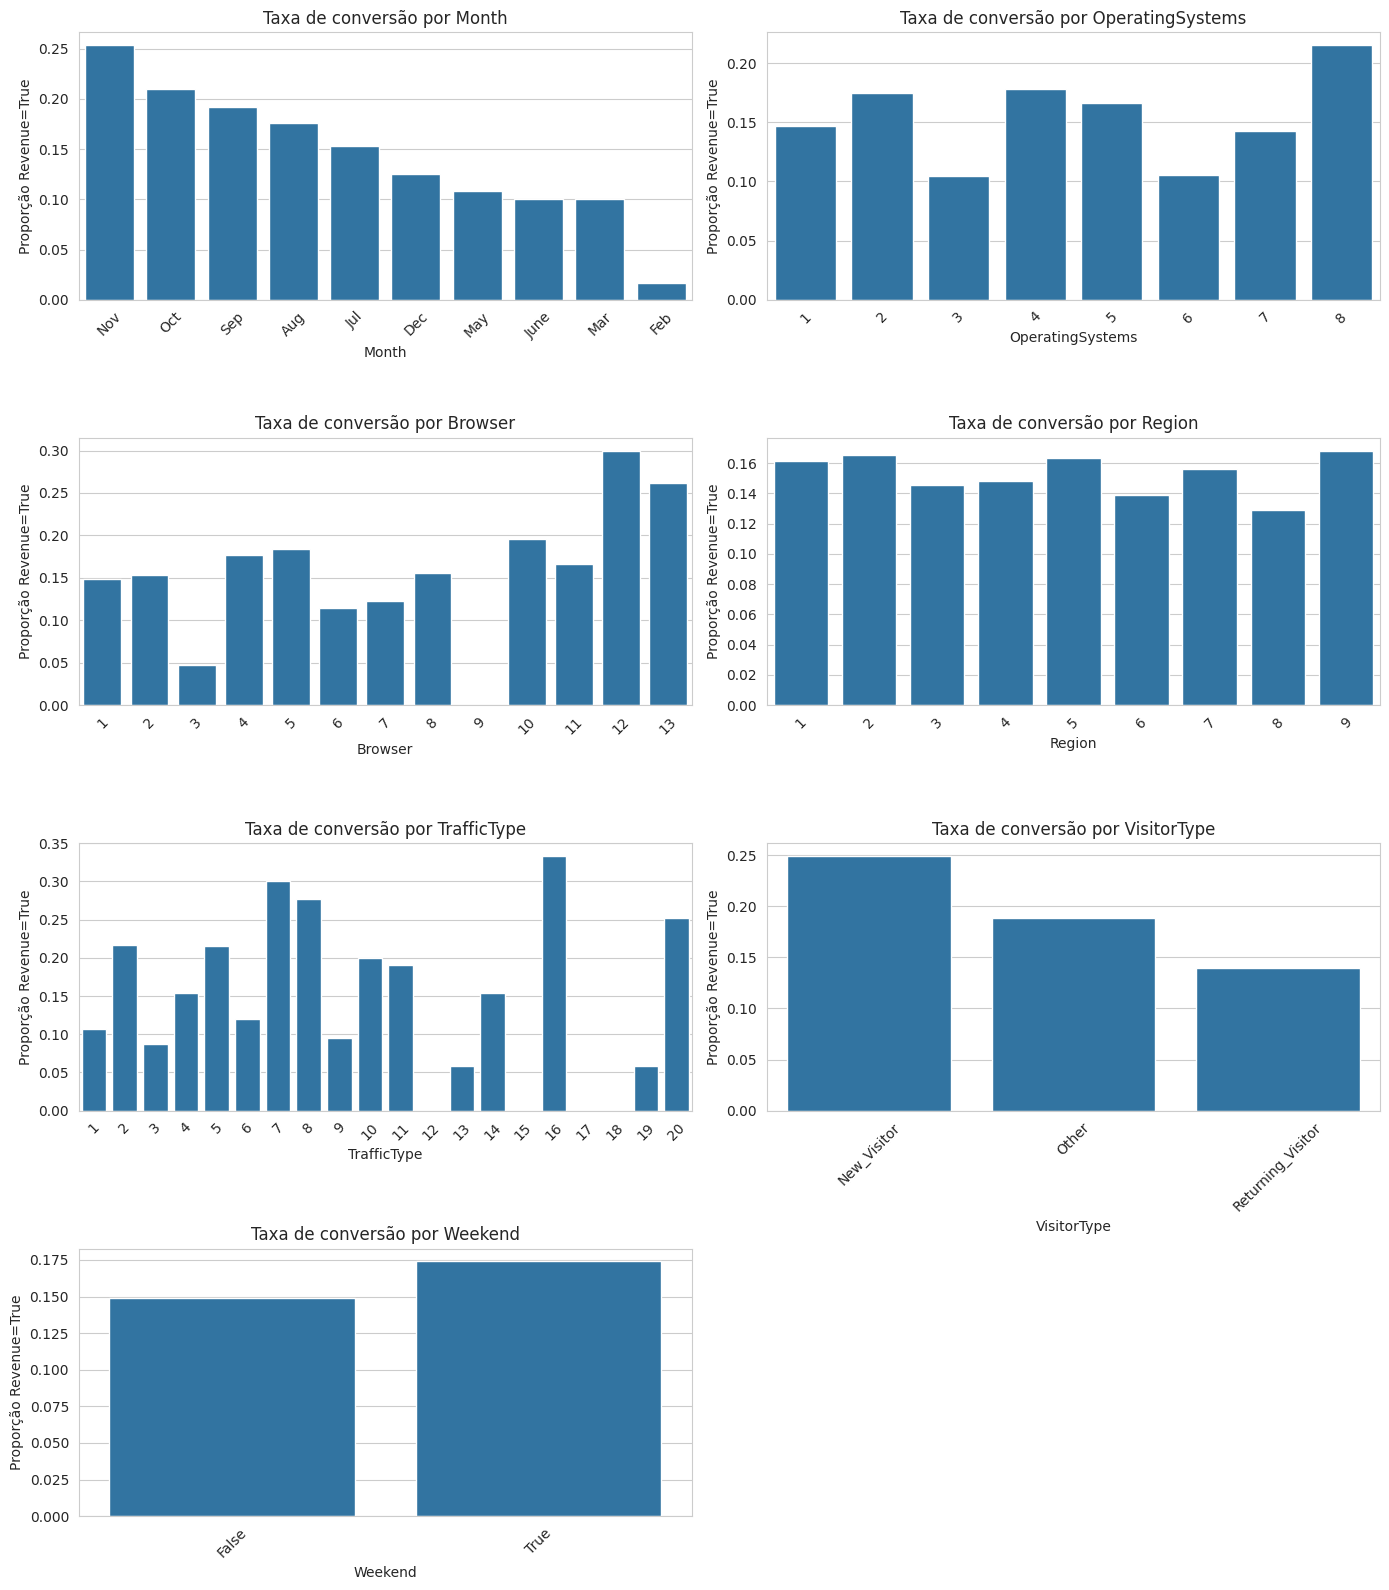

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(atributos_categoricos):
    taxa_conversao = df.groupby(col)['Revenue'].mean().sort_values(ascending=False)
    sns.barplot(x=taxa_conversao.index, y=taxa_conversao.values, ax=axes[i])
    axes[i].set_title(f'Taxa de conversão por {col}')
    axes[i].set_ylabel('Proporção Revenue=True')
    axes[i].tick_params(axis='x', rotation=45)

fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()


### Correlação entre atributos numéricos

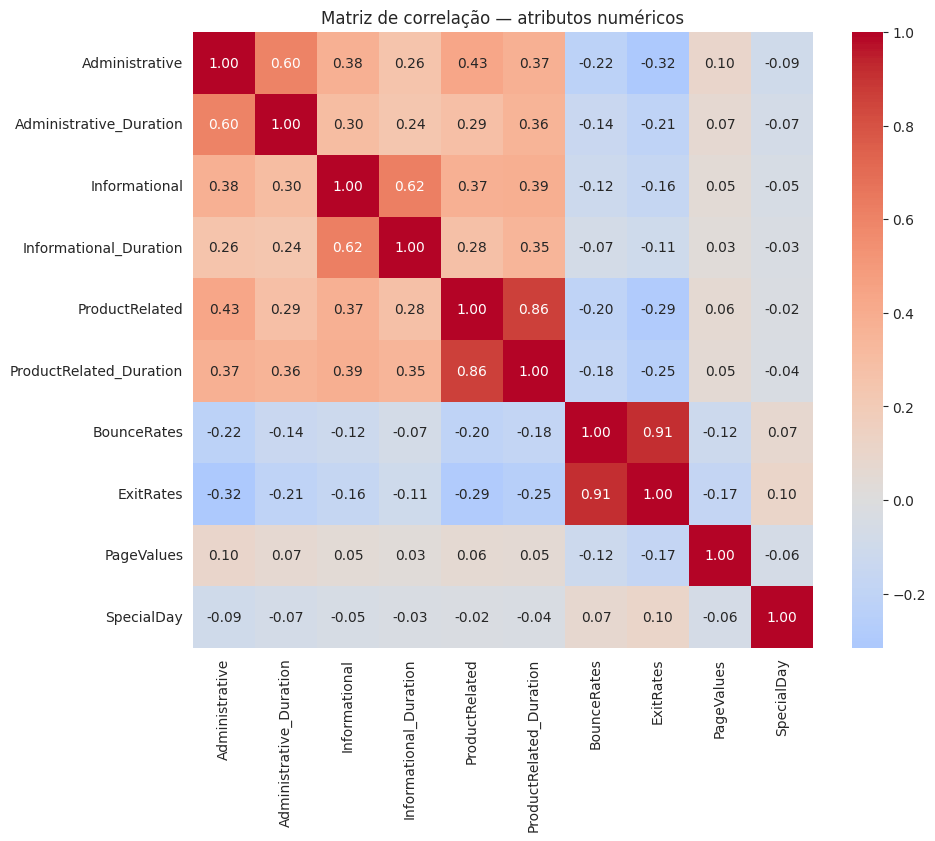

In [ ]:
plt.figure(figsize=(10, 8))
corr = df[atributos_numericos].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlação — atributos numéricos')
plt.show()


### Interpretação dos achados

**Balanceamento:** confirmado o desbalanceamento — 10.422 sessões sem compra (84,53%) contra 1.908 com compra (15,47%). Reforça a necessidade de métricas além de acurácia (F1/precisão/recall da classe positiva) nas próximas seções.

**Sem valores faltantes** em nenhuma das 18 colunas — não há necessidade de imputação.

**Distribuições:** todos os 10 atributos numéricos são fortemente assimétricos à direita (a maioria das sessões tem valores próximos de zero — ex.: `PageValues` é zero para a grande maioria dos visitantes, `BounceRates`/`ExitRates` concentram-se perto de 0 com uma cauda longa até 0,2). Isso é esperado no comportamento de navegação: a maior parte das sessões é curta e superficial, poucas são engajadas.

**Atributos mais separadores em relação ao alvo (boxplots):**
- `PageValues` é o mais discriminativo de longe: sessões com compra têm mediana e dispersão muito mais altas que sessões sem compra — coerente, já que essa métrica é derivada de valor de e-commerce.
- `ExitRates` e `BounceRates` são visivelmente menores em sessões com compra — visitantes que compram navegam mais e saem menos cedo.
- `ProductRelated` e `ProductRelated_Duration` são levemente maiores em sessões com compra — mais páginas de produto visitadas, mais tempo de navegação.
- `Administrative`, `Informational` e suas durações mostram diferença mais discreta entre as classes.

**Atributos categóricos:**
- `Month` mostra um padrão sazonal forte: novembro tem a maior taxa de conversão (~25%), fevereiro a menor (~2%) — plausível, dado que novembro concentra datas promocionais (ex. Black Friday) no hemisfério norte.
- `VisitorType`: contra a intuição, `New_Visitor` converte mais (~25%) que `Returning_Visitor` (~14%) — vale mencionar essa inversão no diagnóstico.
- `Weekend` tem conversão um pouco maior (~17% vs ~15%).
- `OperatingSystems`, `Browser`, `Region` e `TrafficType` mostram variação entre categorias, mas com ruído considerável em categorias de baixa frequência (ex. `Browser` 9, `TrafficType` 12/15/17/18) — sinal de que algumas categorias raras podem não generalizar bem.

**Correlação entre numéricos:** há pares fortemente correlacionados — `BounceRates`/`ExitRates` (0,91), `ProductRelated`/`ProductRelated_Duration` (0,86), e em menor grau `Administrative`/`Administrative_Duration` (0,60) e `Informational`/`Informational_Duration` (0,62). Essa redundância é importante para a Seção 4: modelos baseados em distância (kNN) são mais sensíveis a atributos redundantes e à escala das variáveis do que árvores de decisão.

## Seção 3 — Preparação

### Limpeza e verificação de faltantes

Já verificamos na Seção 2 que o dataset não tem valores faltantes. Antes de seguir, checamos duplicatas e o tipo de cada coluna.

In [ ]:
# Checagem de duplicatas
n_duplicatas = df.duplicated().sum()
print(f"Linhas duplicadas: {n_duplicatas}")

# Decisão: mantivemos as duplicatas. A documentação do dataset informa que cada sessão é
# de um usuário distinto ao longo de 1 ano; 125 linhas idênticas em 12.330 (~1%) é
# plausível como coincidência de padrão de navegação (muitos atributos são contagens/
# categorias com poucos valores possíveis), não indício de erro de coleta. Dado o volume
# desprezível (~1%), o impacto na modelagem é mínimo e optamos por não removê-las.


### Codificação de categóricos

Separamos os atributos em três grupos:
- **Numéricos contínuos**: já prontos para uso direto (`Administrative`, `..._Duration`, `BounceRates`, `ExitRates`, `PageValues`, `SpecialDay`).
- **Categóricos nominais** (sem ordem): `Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType` → one-hot encoding.
- **Booleano**: `Weekend` → mapeado para 0/1.

Usamos one-hot (e não codificação ordinal) porque não há ordem natural entre, por exemplo, `Browser` código 2 e código 5 — tratar como número induziria o modelo a assumir uma relação de magnitude que não existe.

In [ ]:
df_prep = df.copy()

# Alvo e Weekend como booleano -> inteiro
df_prep['Revenue'] = df_prep['Revenue'].astype(int)
df_prep['Weekend'] = df_prep['Weekend'].astype(int)

categoricos_nominais = ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

df_prep = pd.get_dummies(df_prep, columns=categoricos_nominais, drop_first=True)

print(f"Formato antes: {df.shape}")
print(f"Formato depois do one-hot: {df_prep.shape}")
df_prep.head()


Formato antes: (12330, 18)
Formato depois do one-hot: (12330, 69)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Weekend,Revenue,Month_Dec,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_Other,VisitorType_Returning_Visitor,OperatingSystems_2,OperatingSystems_3,OperatingSystems_4,OperatingSystems_5,OperatingSystems_6,OperatingSystems_7,OperatingSystems_8,Browser_2,Browser_3,Browser_4,Browser_5,Browser_6,Browser_7,Browser_8,Browser_9,Browser_10,Browser_11,Browser_12,Browser_13,Region_2,Region_3,Region_4,Region_5,Region_6,Region_7,Region_8,Region_9,TrafficType_2,TrafficType_3,TrafficType_4,TrafficType_5,TrafficType_6,TrafficType_7,TrafficType_8,TrafficType_9,TrafficType_10,TrafficType_11,TrafficType_12,TrafficType_13,TrafficType_14,TrafficType_15,TrafficType_16,TrafficType_17,TrafficType_18,TrafficType_19,TrafficType_20
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,0,0,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,0,0,False,True,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,0,0,False,True,False,False,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,0,0,False,True,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,1,0,False,True,False,False,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


### Divisão em treino, validação e teste

Split estratificado por `Revenue` (preserva a proporção ~85/15 nas três partições), com semente fixa para reprodutibilidade.

Proporções escolhidas: **60% treino / 20% validação / 20% teste**. Justificativa: a busca de hiperparâmetros (Seção 4) precisa de um conjunto de validação com volume suficiente para estimativas estáveis, e 20% de ~12.330 sessões (~2.466) é adequado para isso sem reduzir demais o treino. O teste fica reservado e só é tocado na Seção 5.

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

X = df_prep.drop(columns=['Revenue'])
y = df_prep['Revenue']

# Primeiro separa teste (20%)
X_temp, X_teste, y_temp, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Depois separa treino (60% do total) e validação (20% do total) a partir do restante (80%)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED
)  # 0.25 de 80% = 20% do total

print(f"Treino:    {X_treino.shape[0]} linhas ({y_treino.mean():.3%} positivos)")
print(f"Validação: {X_val.shape[0]} linhas ({y_val.mean():.3%} positivos)")
print(f"Teste:     {X_teste.shape[0]} linhas ({y_teste.mean():.3%} positivos)")


Treino:    7398 linhas (15.477% positivos)
Validação: 2466 linhas (15.450% positivos)
Teste:     2466 linhas (15.491% positivos)


In [ ]:
from sklearn.preprocessing import StandardScaler

# kNN é baseado em distância — sem escalonar, atributos de maior magnitude (ex.: as
# colunas de duração, que chegam à casa dos milhares) dominam o cálculo de distância
# em relação a atributos de escala pequena (ex.: BounceRates, dummies 0/1), fazendo o
# kNN ignorar na prática a maioria dos atributos. O scaler é ajustado SOMENTE no treino,
# para não vazar informação de validação/teste.
scaler = StandardScaler()
X_treino_esc = scaler.fit_transform(X_treino)
X_val_esc = scaler.transform(X_val)
X_teste_esc = scaler.transform(X_teste)


**Nota:** a partir daqui, `X_teste`/`y_teste` só devem ser usados na Seção 5, uma única vez, para avaliar os modelos campeões. Toda a busca de hiperparâmetros da Seção 4 usa exclusivamente `X_treino`/`X_val`.

# Seção 4 — Baselines com busca de hiperparâmetros

**kNN**: melhor k

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

ks = [1, 3, 5, 9, 15, 25, 51]
acc_val_knn = []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_treino_esc, y_treino)
    acc = m.score(X_val_esc, y_val)
    acc_val_knn.append(acc)

melhor_k = ks[int(np.argmax(acc_val_knn))]
plt.figure(figsize=(6.5, 3.6))
plt.plot(ks, acc_val_knn, "o-", color="r")
plt.axvline(melhor_k, ls=":", color="#333333")
plt.xlabel("k"); plt.ylabel("acurácia de validação"); plt.title(f"Campeão: k = {melhor_k}")
plt.show()


 **Árvore de decisão**: melhores max_depth e min_samples

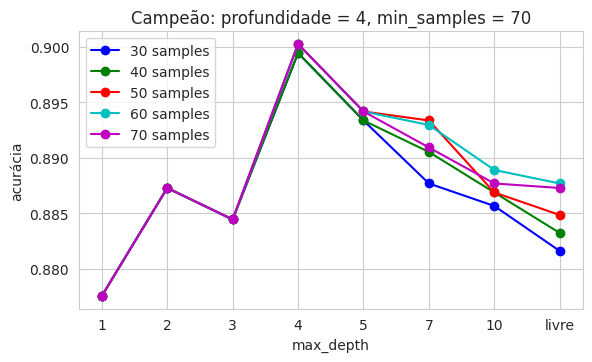

In [ ]:
from sklearn.tree import DecisionTreeClassifier

min_samples = [30, 40, 50, 60, 70]
profundidades = [1, 2, 3, 4, 5, 7, 10, None]

acc_val_arv = []
for s in min_samples:
  acc_val_arv_p = []
  for p in profundidades:
      m = DecisionTreeClassifier(max_depth=p, min_samples_split=s, random_state=0).fit(X_treino, y_treino)
      acc_val_arv_p.append(m.score(X_val, y_val))
  acc_val_arv.append(acc_val_arv_p)

melhor_s = 0
melhor_p = 0
for i, acc in enumerate(acc_val_arv):
  melhor = int(np.argmax(acc))
  if acc[melhor] >= acc_val_arv[melhor_s][melhor_p]:
    melhor_s = i
    melhor_p = melhor

plt.figure(figsize=(6.5, 3.6))
colors = ['b', 'g', 'r', 'c', 'm']
rotulos = [str(p) if p else "livre" for p in profundidades]
for i, s in enumerate(min_samples):
  plt.plot(rotulos, acc_val_arv[i], "o-", color=colors[i], label=f"{s} samples")

plt.title(f"Campeão: profundidade = {profundidades[melhor_p]}, min_samples = {min_samples[melhor_s]}")

plt.xlabel("max_depth"); plt.ylabel("acurácia"); plt.legend()
plt.show()


#Seção 5 — Resultado e diagnóstico

In [ ]:
from mlxtend.evaluate import bias_variance_decomp

# kNN agora usa o k campeão encontrado acima, nos dados ESCALADOS
m1 = KNeighborsClassifier(n_neighbors=melhor_k).fit(X_treino_esc, y_treino)

# Árvore de decisão para profundidade = 4 e min_samples = 70 (campeã da Seção 4),
# nos dados originais — árvore não precisa de escalonamento
m2 = DecisionTreeClassifier(max_depth=4, min_samples_split=70, random_state=0).fit(X_treino.values, y_treino.values)

modelos_info = [
    {'nome': 'kNN', 'modelo': m1, 'Xtr': X_treino_esc, 'Xte': X_teste_esc},
    {'nome': 'Árvore de decisão', 'modelo': m2, 'Xtr': X_treino.values, 'Xte': X_teste.values},
]

for m_info in modelos_info:
    m = m_info['modelo']
    _, avg_bias, avg_var = bias_variance_decomp(
        m,
        m_info['Xtr'], y_treino.values,
        m_info['Xte'], y_teste.values,
        num_rounds=20,
        loss='mse',
        random_seed=23
    )
    print(f"{m_info['nome']}")
    print('Viés: %.3f' % avg_bias)
    print('Variância: %.3f' % avg_var)
    print('Acurácia: %.3f' % m.score(m_info['Xte'], y_teste))
    print('------------------------')
    print()


No conjunto de teste, os modelos tiveram desempenhos distintos, considerando o viés e a variância. O **kNN**, com configuração campeã de `k = 9` (escolhida com os atributos escalonados via `StandardScaler`, necessário porque o kNN usa distância e os atributos originais têm escalas muito diferentes), obteve `viés = 0.124` e `variância = 0.031`. A **Árvore de decisão**, com configuração `max_depth = 4` e `min_samples_split = 70`, obteve `viés = 0.080` e `variância = 0.031`.

Note que o escalonamento não trouxe a melhora esperada para o kNN: comparado à versão sem escalonar (viés 0.129, variância 0.020, acurácia 0.853), o viés caiu pouco e a variância aumentou, resultando em acurácia levemente pior (0.839). Uma explicação plausível é a alta dimensionalidade introduzida pelo one-hot (~68 colunas, a maioria delas dummies pouco informativas de Browser/Region/TrafficType): mesmo com escalas equalizadas, o cálculo de distância do kNN é afetado pelo "acúmulo de ruído" de tantas dimensões pouco discriminativas, um problema conhecido do kNN em espaços de alta dimensão. Isso reforça que o escalonamento era metodologicamente necessário (sem ele, a distância era dominada apenas pelas colunas de duração), mas não é suficiente sozinho para tornar o kNN competitivo neste problema.

Como os dois modelos priorizam trade-offs diferentes de viés e variância, usamos a **acurácia no teste** como critério final de comparação: a Árvore obteve `acurácia = 0.898`, enquanto o kNN obteve `acurácia = 0.839`. A Árvore de decisão apresenta tanto menor viés quanto acurácia superior, sendo o modelo com melhor desempenho nesta entrega.

### Próximos passos

Para a Entrega 2, os próximos passos incluem: (1) testar modelos mais robustos ao trade-off viés-variância, como Random Forest e Gradient Boosting; (2) tratar o desbalanceamento das classes diretamente (`class_weight='balanced'`, SMOTE), já que a acurácia isolada pode mascarar desempenho fraco na classe minoritária (compra); (3) avaliar métricas de precisão, recall e F1 da classe positiva além da acurácia e da decomposição viés-variância, para capturar melhor a capacidade dos modelos de identificar sessões de compra; (4) usar validação cruzada em vez de um único split de validação, reduzindo a variância da estimativa de hiperparâmetro; (5) para o kNN, avaliar redução de dimensionalidade (ex.: PCA, ou remover categóricas de alta cardinalidade e baixa relevância) para mitigar o efeito da alta dimensionalidade observado nesta entrega.

## Seção 6 — Declaração de uso de IA

Eduardo usou o Claude (Anthropic) para estruturar o notebook, sugerir/revisar código de exploração, preparação e busca de hiperparâmetros, e para identificar um problema metodológico no baseline de kNN (ausência de escalonamento dos atributos, relevante por ser um modelo baseado em distância) — corrigido com `StandardScaler` ajustado apenas no treino. Wallace desenvolveu sua parte (incluindo a análise de viés e variância com `bias_variance_decomp`, da biblioteca mlxtend) sem uso de IA.

Verificação: todo código sugerido foi executado e conferido contra os outputs reais (dimensões, métricas, gráficos) antes de incorporado. As decisões de modelagem (proporções do split, manutenção das duplicatas, escalonamento do kNN) foram entendidas por ambos e podem ser justificadas na arguição, cada um por sua parte.